In [498]:
# for the data manupilation
import numpy as np
import pandas as pd
# for the plot and statistics
import matplotlib.pyplot as plt
import seaborn as sns

# for the machine learning model
import tensorflow as tf 
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from tensorflow.keras.layers import Dense
from keras.models import Sequential
from sklearn.metrics import mean_squared_error,accuracy_score,log_loss,recall_score,precision_score
from sklearn.model_selection import train_test_split
from keras.optimizers import Adam
from keras import regularizers



In [499]:
train_df = pd.read_csv('train.csv',)
test_df = pd.read_csv('test.csv')
train_df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


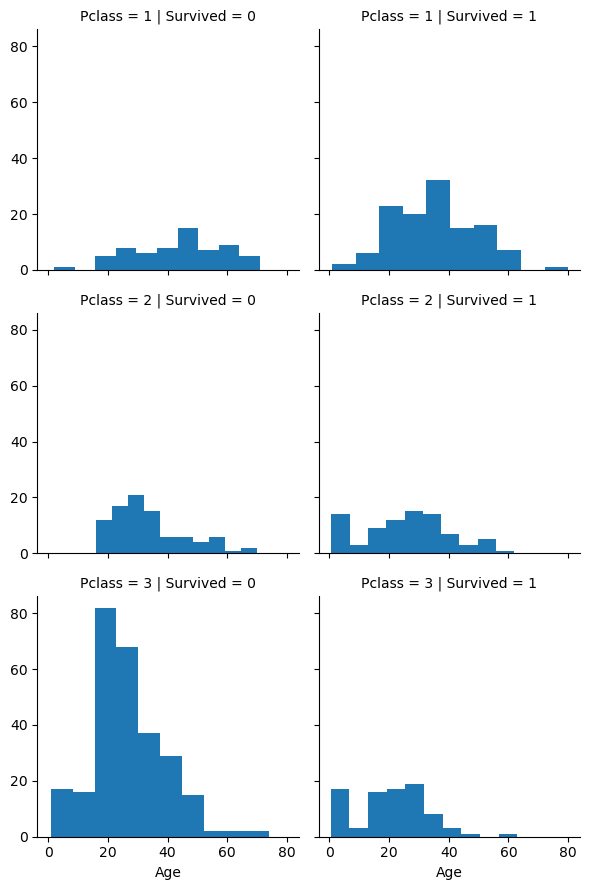

In [500]:
k = sns.FacetGrid(train_df,col='Survived',row='Pclass')
k.map(plt.hist,'Age')
train_df.info()

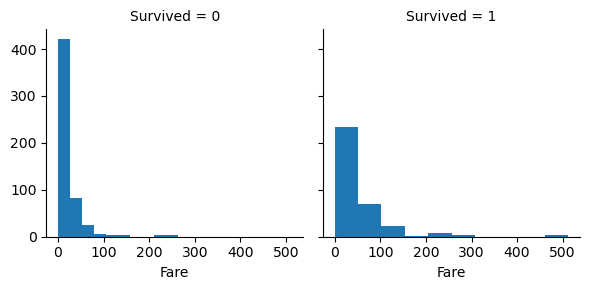

In [501]:

train_df.groupby(['Embarked','Sex','Pclass']).Survived.mean()


g = sns.FacetGrid(train_df,col='Survived')
g.map(plt.hist,'Fare')

c:\Users\nitro\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


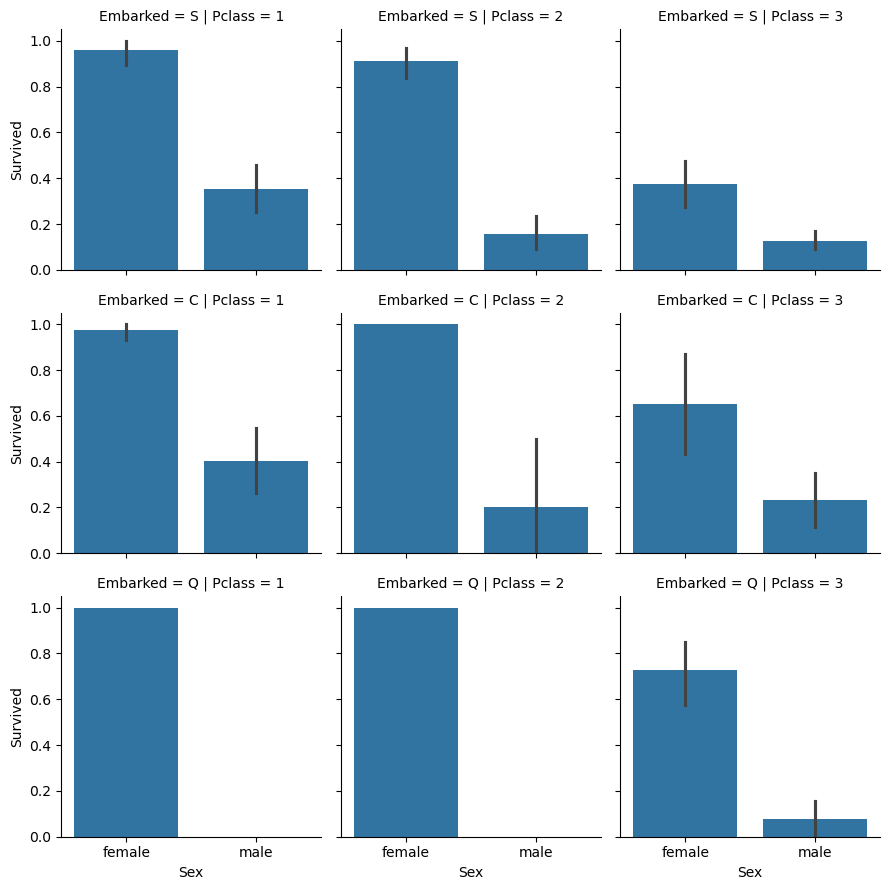

In [502]:
g = sns.FacetGrid(train_df,col='Pclass',row='Embarked')
g.map(sns.barplot,'Sex','Survived')

c:\Users\nitro\anaconda3\Lib\site-packages\seaborn\axisgrid.py:718: UserWarning: Using the barplot function without specifying `order` is likely to produce an incorrect plot.
  warnings.warn(warning)


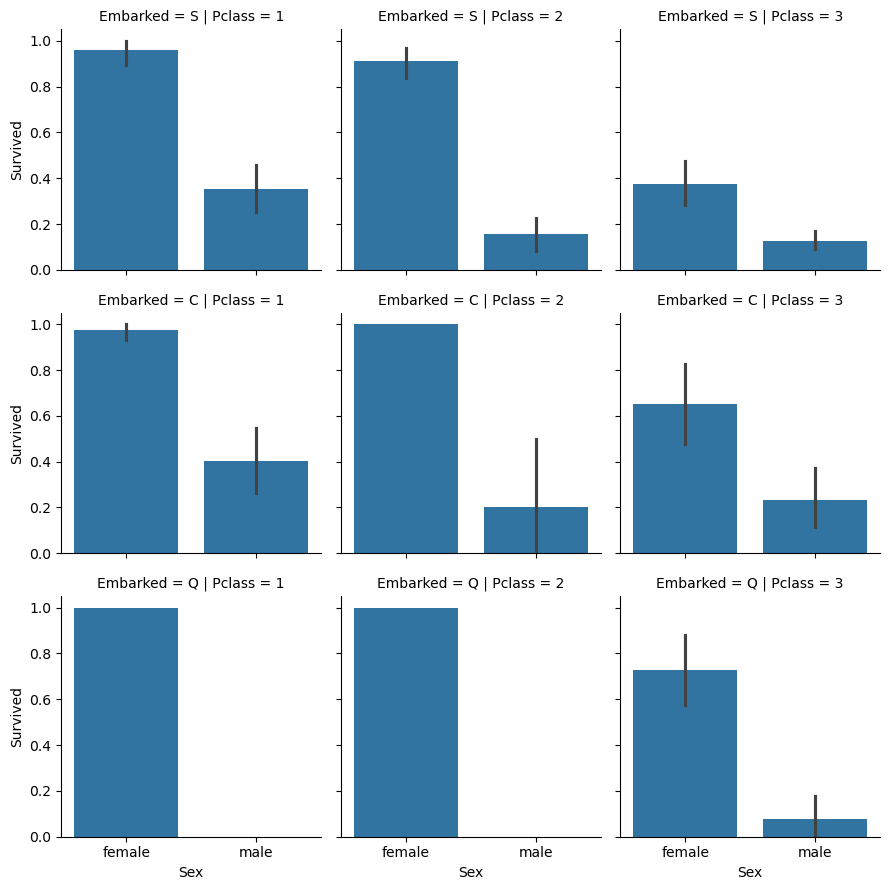

In [503]:
g = sns.FacetGrid(train_df,col='Pclass',row='Embarked')
g.map(sns.barplot,'Sex','Survived')

In [504]:
train_df = train_df.drop(['Ticket', 'Cabin','PassengerId'], axis=1)
test_df = test_df.drop(['Ticket', 'Cabin','PassengerId'], axis=1)
combine = [train_df, test_df]

In [505]:

for i in combine:
    i['title'] = i.Name.str.extract(' ([A-Za-z]+)\.',expand =False)
pd.crosstab(train_df['title'],train_df['Sex'])

Sex,female,male
title,,
Capt,0,1
Col,0,2
Countess,1,0
Don,0,1
Dr,1,6
Jonkheer,0,1
Lady,1,0
Major,0,2
Master,0,40


In [506]:
for data in combine:
    data['title'] = data['title'].replace(['Lady', 'Countess','Capt', 'Col',\
 	'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona'], 'Rare')
    data['title'] = data['title'].replace('Mlle', 'Miss')
    data['title'] = data['title'].replace('Ms', 'Miss')
    data['title'] = data['title'].replace('Mme', 'Mrs')
train_df.groupby('title').Survived.mean()

title
Master    0.575000
Miss      0.702703
Mr        0.156673
Mrs       0.793651
Rare      0.347826
Name: Survived, dtype: float64

In [507]:
for data in combine:
    data['Age'] = data.groupby(['Pclass','title','Sex'])['Age'].transform(lambda x: x.fillna(x.median()))
train_df['Age'].isna().sum()
train_df = train_df.dropna()
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 889 entries, 0 to 890
Data columns (total 10 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   Survived  889 non-null    int64  
 1   Pclass    889 non-null    int64  
 2   Name      889 non-null    object 
 3   Sex       889 non-null    object 
 4   Age       889 non-null    float64
 5   SibSp     889 non-null    int64  
 6   Parch     889 non-null    int64  
 7   Fare      889 non-null    float64
 8   Embarked  889 non-null    object 
 9   title     889 non-null    object 
dtypes: float64(2), int64(4), object(4)
memory usage: 76.4+ KB


In [508]:
def ageplace(df):
    if df <5:
        return 'baby'
    elif df >=5 and df< 18:
        return 'teenage'
    elif df>=18 and df<40:
        return 'young'
    elif df>=40 and df < 55:
        return 'middleage'
    else:
        return 'old'
train_df['Age'] = train_df.Age.map(ageplace)
test_df['Age'] = test_df.Age.map(ageplace)
train_df.head()


C:\Users\nitro\AppData\Local\Temp\ipykernel_27780\2564239099.py:12: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df['Age'] = train_df.Age.map(ageplace)


,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,title
0,0,3,"Braund, Mr. Owen Harris",male,young,1,0,7.2500,S,Mr
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,young,1,0,71.2833,C,Mrs
2,1,3,"Heikkinen, Miss. Laina",female,young,0,0,7.9250,S,Miss
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,young,1,0,53.1000,S,Mrs
4,0,3,"Allen, Mr. William Henry",male,young,0,0,8.0500,S,Mr


In [509]:
train_df.groupby(['Pclass','Sex']).Survived.mean()

Pclass  Sex   
1       female    0.967391
        male      0.368852
2       female    0.921053
        male      0.157407
3       female    0.500000
        male      0.135447
Name: Survived, dtype: float64

In [510]:
train_df['Pclass_Sex'] = train_df['Pclass'].astype(str) + '_' + train_df['Sex']
test_df['Pclass_Sex'] = test_df['Pclass'].astype(str) + '_' + test_df['Sex']

C:\Users\nitro\AppData\Local\Temp\ipykernel_27780\4069116046.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  train_df['Pclass_Sex'] = train_df['Pclass'].astype(str) + '_' + train_df['Sex']


In [511]:
 
train_df.head()

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Fare,Embarked,title,Pclass_Sex
0,0,3,"Braund, Mr. Owen Harris",male,young,1,0,7.2500,S,Mr,3_male
1,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,young,1,0,71.2833,C,Mrs,1_female
2,1,3,"Heikkinen, Miss. Laina",female,young,0,0,7.9250,S,Miss,3_female
3,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,young,1,0,53.1000,S,Mrs,1_female
4,0,3,"Allen, Mr. William Henry",male,young,0,0,8.0500,S,Mr,3_male


In [512]:
test_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 418 entries, 0 to 417
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Pclass      418 non-null    int64  
 1   Name        418 non-null    object 
 2   Sex         418 non-null    object 
 3   Age         418 non-null    object 
 4   SibSp       418 non-null    int64  
 5   Parch       418 non-null    int64  
 6   Fare        417 non-null    float64
 7   Embarked    418 non-null    object 
 8   title       418 non-null    object 
 9   Pclass_Sex  418 non-null    object 
dtypes: float64(1), int64(3), object(6)
memory usage: 32.8+ KB


In [513]:
test_df['Fare'] = test_df.groupby(['Pclass','Embarked']).Fare.transform(lambda x: x.fillna(x.mean()))

[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 4.0125, 5.0, 6.2375, 6.4375, 6.45, 6.4958, 6.4958, 6.75, 6.75, 6.8583, 6.95, 6.975, 6.975, 7.0458, 7.05, 7.05, 7.05, 7.05, 7.05, 7.05, 7.05, 7.0542, 7.0542, 7.125, 7.125, 7.125, 7.125, 7.1417, 7.225, 7.225, 7.225, 7.225, 7.225, 7.225, 7.225, 7.225, 7.225, 7.225, 7.225, 7.225, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.2292, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.25, 7.3125, 7.4958, 7.4958, 7.4958, 7.5208, 7.55, 7.55, 7.55, 7.55, 7.6292, 7.65, 7.65, 7.65, 7.65, 7.725, 7.7292, 7.7333, 7.7333, 7.7333, 7.7333, 7.7375, 7.7375, 7.7417, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.75, 7.775, 7.775, 7.775, 7.775, 7.775, 7.775, 7.775, 7.775, 7.775, 7.775, 7.775, 7

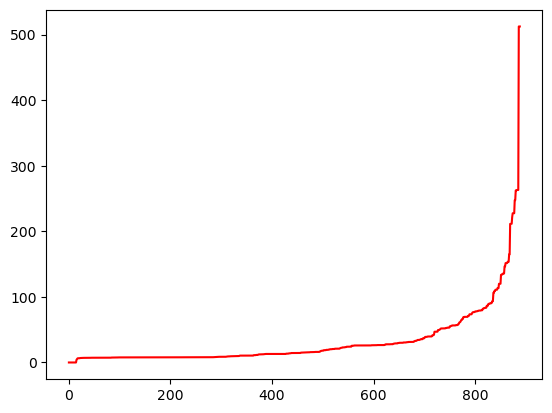

In [514]:
fair = train_df.Fare.sort_values()
fair =  list(fair)
print(fair)
plt.plot(range(len(fair)),fair,color = 'red')
plt.show()

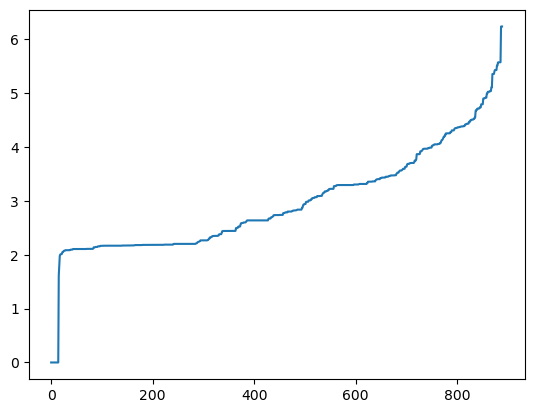

In [515]:
combine = [train_df,test_df]
for data in combine:
    data['Farelog'] = np.log1p(data['Fare'])
plt.plot(range(len(train_df['Farelog'])),list(train_df['Farelog'].sort_values()))
plt.show()

In [516]:

train_df['Fare'], bins = pd.cut(train_df['Farelog'], 5, labels=False, retbins=True)
bins[0], bins[-1] = -np.inf, np.inf
test_df['Fare'] = pd.cut(test_df['Farelog'], bins=bins, labels=False)
train_df = train_df.drop(['Farelog','Name',],axis=1)
test_df = test_df.drop(['Farelog','Name',],axis=1)
train_df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,title,Pclass_Sex
0,0,3,male,young,1,0,1,S,Mr,3_male
1,1,1,female,young,1,0,3,C,Mrs,1_female
2,1,3,female,young,0,0,1,S,Miss,3_female
3,1,1,female,young,1,0,3,S,Mrs,1_female
4,0,3,male,young,0,0,1,S,Mr,3_male


In [517]:
combine = [train_df,test_df]
for data in combine:
    data['Family_Size'] = data['SibSp'] + data['Parch']
    data['Is_Alone'] = 0
    data.loc[data.Family_Size > 0,'Is_Alone'] = 1
    data.drop(['SibSp','Parch'],axis=1,inplace=True)
train_df.head()
train_df.groupby('Is_Alone').Survived.mean()

Is_Alone
0    0.300935
1    0.505650
Name: Survived, dtype: float64

In [518]:
train_df.groupby(['Pclass','Age']).Survived.mean()

Pclass  Age      
1       baby         0.666667
        middleage    0.542169
        old          0.346154
        teenage      1.000000
        young        0.741935
2       baby         1.000000
        middleage    0.482759
        old          0.250000
        teenage      0.818182
        young        0.403226
3       baby         0.517241
        middleage    0.052632
        old          0.142857
        teenage      0.301887
        young        0.233516
Name: Survived, dtype: float64

In [519]:
age_mapping = {
        'baby': 0,
        'teenage': 1,
        'young': 2,
        'middleage': 3,
        'old': 4
    }
train_df['Age'] = train_df['Age'].map(age_mapping)
test_df['Age'] = test_df['Age'].map(age_mapping)

In [520]:
train_df['isFemaleBoy'] = (train_df['Sex'] == 'female') | (train_df['Age'] == 0)
test_df['isFemaleBoy'] = (test_df['Sex'] == 'female') | (test_df['Age'] == 0)
train_df.groupby('isFemaleBoy').Survived.mean()

isFemaleBoy
False    0.167273
True     0.731563
Name: Survived, dtype: float64

Pclass  Age
1       0      0.666667
        1      1.000000
        2      0.741935
        3      0.542169
        4      0.346154
2       0      1.000000
        1      0.818182
        2      0.403226
        3      0.482759
        4      0.250000
3       0      0.517241
        1      0.301887
        2      0.233516
        3      0.052632
        4      0.142857
Name: Survived, dtype: float64

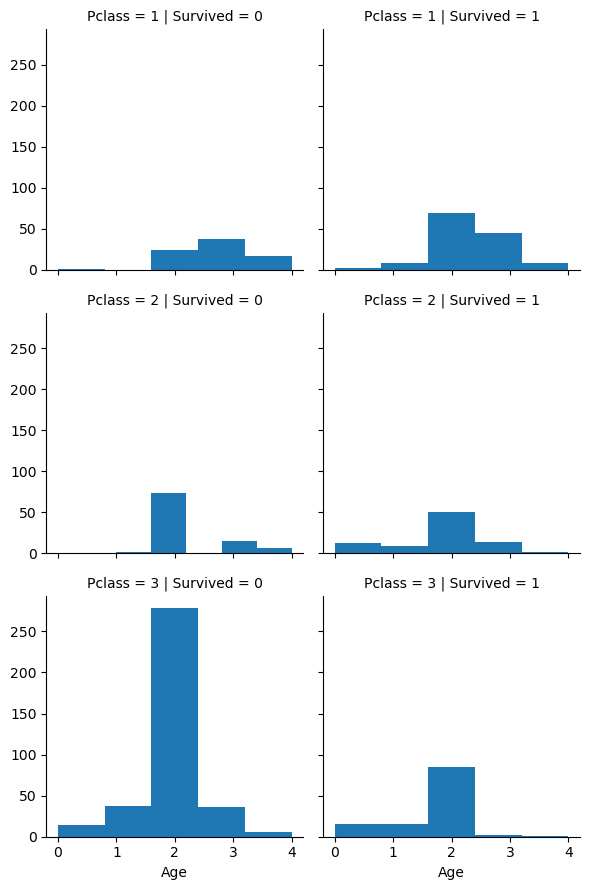

In [521]:
l = sns.FacetGrid(train_df,col='Survived',row='Pclass')
l.map(plt.hist,'Age',bins=5)
train_df.groupby(['Pclass','Age']).Survived.mean()

In [522]:
train_df['AgePclass'] = train_df['Age'] * train_df['Pclass']
test_df['AgePclass'] = test_df['Age'] * test_df['Pclass']
train_df.head()

,Survived,Pclass,Sex,Age,Fare,Embarked,title,Pclass_Sex,Family_Size,Is_Alone,isFemaleBoy,AgePclass
0,0,3,male,2,1,S,Mr,3_male,1,1,False,6
1,1,1,female,2,3,C,Mrs,1_female,1,1,True,2
2,1,3,female,2,1,S,Miss,3_female,0,0,True,6
3,1,1,female,2,3,S,Mrs,1_female,1,1,True,2
4,0,3,male,2,1,S,Mr,3_male,0,0,False,6


In [523]:
train_df = pd.get_dummies(train_df,columns=['Sex','title','Embarked','Age','Fare','Pclass_Sex'],drop_first=True,)
test_df = pd.get_dummies(test_df,columns=['Sex','title','Embarked','Age','Fare','Pclass_Sex'],drop_first=True,)

In [524]:
test_df.head()
print(train_df.shape,test_df.shape)


(889, 26) (418, 25)


In [525]:
x_train = train_df.drop('Survived',axis=1)
y_train = train_df['Survived']
cv_error = []
train_error = []
Recall = []
Precision = []
accuracy = []
scaler = StandardScaler()
x_train,x_cv,y_train,y_cv = train_test_split(x_train,y_train,test_size=0.05)
for i in range(2,3):
    tf.keras.backend.clear_session()
    tf.random.set_seed(42)
    poly = PolynomialFeatures(i,include_bias=False)
    x_train_poly = poly.fit_transform(x_train)
    x_cv_poly = poly.fit_transform(x_cv)
    test_df = poly.fit_transform(test_df)
    x_train_poly = scaler.fit_transform(x_train_poly)
    x_cv_poly = scaler.transform(x_cv_poly)
    test_df = scaler.transform(test_df)
    regulizer = regularizers.l2(0.07)
    model = Sequential([
                Dense(units=80  , activation='relu', kernel_regularizer=regulizer),
                Dense(units=55, activation='relu', kernel_regularizer=regulizer),
                Dense(units=20, activation='relu', kernel_regularizer=regulizer),
                Dense(units=1, activation='linear', kernel_regularizer=regulizer)
            ])
    model.compile(
        loss=tf.keras.losses.BinaryCrossentropy(from_logits=True),
        optimizer=Adam(0.01)
    )
    model.fit(x_train_poly,y_train,epochs=70)
    yh = tf.sigmoid(model.predict(x_cv_poly)).numpy()
    yh_metrice = (yh > 0.35).astype(int)
    p_tr = tf.sigmoid(model.predict(x_train_poly))
    train_error.append(log_loss(y_train, p_tr))
    cv_error.append(log_loss(y_cv,yh))
    Precision.append(precision_score(y_cv,yh_metrice))
    Recall.append(recall_score(y_cv,yh_metrice))
    accuracy.append(accuracy_score(y_cv,yh_metrice))

Epoch 1/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - loss: 4.0239 
Epoch 2/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.8327
Epoch 3/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7060
Epoch 4/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7056
Epoch 5/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6910
Epoch 6/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6875
Epoch 7/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6988
Epoch 8/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6899
Epoch 9/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6852
Epoch 10/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6792
Epoch 11/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6695
Epoch 12/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6622
Epoch 13/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6596
Epoch 14/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.6604
Epoch 15/70
27/27 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.6550
Epoch 16/70
27/27 

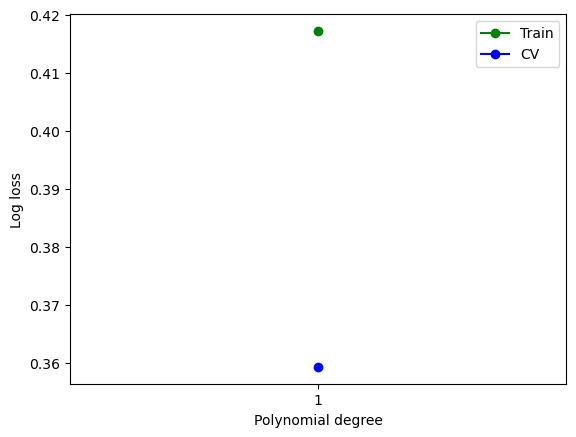

In [526]:
degrees = range(1, len(cv_error) + 1)
plt.plot(degrees, train_error, marker='o', color='green', label='Train')
plt.plot(degrees, cv_error,    marker='o', color='blue',  label='CV')
plt.xlabel('Polynomial degree')
plt.ylabel('Log loss')
plt.xticks(list(degrees))
plt.legend()
plt.show()

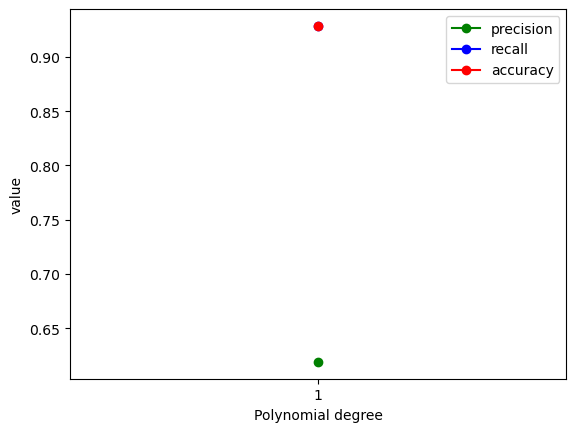

In [527]:
degrees = range(1, len(cv_error) + 1)   # safer than range(1, i+1)
plt.plot(degrees, Precision, marker='o', color='green', label='precision')
plt.plot(degrees, Recall,    marker='o', color='blue',  label='recall')
plt.plot(degrees, Recall,    marker='o', color='red',  label='accuracy')
plt.xlabel('Polynomial degree')
plt.ylabel('value')
plt.xticks(list(degrees))
plt.legend()
plt.show()

In [529]:
test_ids = pd.read_csv('test.csv')['PassengerId'] 
result = tf.sigmoid(model.predict(test_df)).numpy().ravel()
final_result = (result > 0.33).astype(int)
submission = pd.DataFrame({'PassengerId': test_ids,'Survived':final_result})
submission.to_csv('submission6.csv',index=False)

14/14 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
